# Tarea 1 · Parte 2: del LLM al clasificador

 En la Parte 1 terminé con un CSV cuyas etiquetas eran provisionales: salían de la sección del diario donde estaba cada nota, y eso no siempre refleja de qué trata. En esta parte hago tres cosas, en este orden:

1. **Etiquetar con un LLM** y comparar con la sección, para ver cuánto ruido tienen mis etiquetas.
2. **Revisar a mano**  los casos donde no coinciden y una muestra al azar, y con eso fijar las etiquetas finales.
3. **Entrenar varios modelos y compararlos** en un test que no toco hasta el final.

Reutilizo dos cosas de las clases. De la de LLMs (llms_a_prueba) tomo que un LLM no «responde» como una persona, sino que calcula una distribución de probabilidad sobre el siguiente token; esa distribución me sirve como medida de confianza. De la de fine-tuning tomo el flujo con Trainer y la métrica F1 macro, que es más justa que la accuracy cuando las clases no están parejas.

> Regla impuesta:  el test se separa después de fijar las etiquetas y antes de entrenar nada. Revisé las etiquetas sin usar ningún modelo entrenado, así que el test no se contamina.

In [1]:
import json
import random
import tempfile
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
cat2id = {c: i for i, c in enumerate(CATEGORIAS)}
id2cat = {i: c for c, i in cat2id.items()}

df = pd.read_csv("datos/noticias.csv")
df = df.rename(columns={"etiqueta": "etiqueta_seccion"})
print(df.shape)
df.etiqueta_seccion.value_counts()

(382, 7)


etiqueta_seccion
economia              99
deportes              98
ciencia_tecnologia    94
politica              91
Name: count, dtype: int64

## 1. El LLM como etiquetador

Para **Qwen2.5-1.5B-Instruct**, corriendo en local en CPU. Es de la misma familia que el Qwen de 0.5B que usamos en clase, pero más grande, y esa diferencia importa: el de 0.5B es muy chico para clasificar noticias con confianza. Elegí uno local para no depender de una API ni de claves, y así cualquiera puede repetir el experimento.

Siguiendo la clase 8, no le pido que escriba texto libre. Le pido una sola letra (A, B, C, D o E) y miro qué probabilidad le da el modelo a cada una en el primer token de su respuesta. De ahí sale la confianza, directo de la distribución del modelo, y no de un número que yo me invente. La opción E es «ninguna de las anteriores». La puse para poder cumplir la regla de la tarea de descartar lo que no encaje en las 4 categorías, sin inventar una quinta.

In [2]:
from transformers import AutoModelForCausalLM, AutoTokenizer

LLM_ID = "Qwen/Qwen2.5-1.5B-Instruct"
tok_llm = AutoTokenizer.from_pretrained(LLM_ID)
llm = AutoModelForCausalLM.from_pretrained(LLM_ID, dtype=torch.float32).eval()

LETRAS = {"A": "politica", "B": "economia", "C": "deportes", "D": "ciencia_tecnologia", "E": "ninguna"}
ids_letras = [tok_llm.encode(l)[0] for l in LETRAS]
assert all(len(tok_llm.encode(l)) == 1 for l in LETRAS), "cada letra debe ser un solo token"

SISTEMA = "Eres editor de un diario peruano. Clasificas cada noticia en una única categoría."
PLANTILLA = (
    "Titular: {titular}\nBajada: {bajada}\n\n"
    "Categorías:\n"
    "A) política (gobierno, Congreso, partidos, elecciones, justicia)\n"
    "B) economía (empresas, mercados, precios, empleo, finanzas, comercio)\n"
    "C) deportes\n"
    "D) ciencia y tecnología (tecnología, internet, IA, ciencia, videojuegos, ambiente)\n"
    "E) ninguna de las anteriores\n\n"
    "Responde solo con la letra."
)

def etiquetar_llm(titular, bajada):
    msgs = [{"role": "system", "content": SISTEMA},
            {"role": "user", "content": PLANTILLA.format(titular=titular, bajada=bajada)}]
    texto = tok_llm.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    ids = tok_llm(texto, return_tensors="pt")
    with torch.no_grad():
        logits = llm(**ids).logits[0, -1]
    p = torch.softmax(logits[ids_letras], dim=-1).numpy()   # solo entre las 5 letras
    return p

# prueba rápida con un titular de cada categoría
for et in CATEGORIAS:
    f = df[df.etiqueta_seccion == et].iloc[0]
    p = etiquetar_llm(f.titular, f.bajada)
    print(f"{et:<20} -> {dict(zip(LETRAS.values(), p.round(2)))}")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

politica             -> {'politica': np.float32(0.84), 'economia': np.float32(0.08), 'deportes': np.float32(0.0), 'ciencia_tecnologia': np.float32(0.0), 'ninguna': np.float32(0.08)}


economia             -> {'politica': np.float32(0.0), 'economia': np.float32(1.0), 'deportes': np.float32(0.0), 'ciencia_tecnologia': np.float32(0.0), 'ninguna': np.float32(0.0)}


deportes             -> {'politica': np.float32(0.0), 'economia': np.float32(0.0), 'deportes': np.float32(1.0), 'ciencia_tecnologia': np.float32(0.0), 'ninguna': np.float32(0.0)}


ciencia_tecnologia   -> {'politica': np.float32(0.0), 'economia': np.float32(0.01), 'deportes': np.float32(0.01), 'ciencia_tecnologia': np.float32(0.75), 'ninguna': np.float32(0.23)}


In [3]:
RUTA_LLM = Path("datos/etiquetas_llm.csv")
if RUTA_LLM.exists() and len(pd.read_csv(RUTA_LLM)) == len(df):
    llm_df = pd.read_csv(RUTA_LLM)
else:
    t0 = time.time()
    probs = np.vstack([etiquetar_llm(f.titular, f.bajada) for f in df.itertuples()])
    print(f"{len(df)} titulares en {time.time() - t0:.0f} s ({(time.time() - t0) / len(df):.2f} s por titular)")
    llm_df = pd.DataFrame(probs, columns=[f"p_{v}" for v in LETRAS.values()])
    llm_df.insert(0, "url", df.url.values)
    llm_df["etiqueta_llm"] = [list(LETRAS.values())[i] for i in probs.argmax(1)]
    llm_df["confianza"] = probs.max(1).round(4)
    llm_df["modelo_llm"] = LLM_ID
    llm_df.to_csv(RUTA_LLM, index=False)

df = df.merge(llm_df[["url", "etiqueta_llm", "confianza", "modelo_llm"]], on="url")
del llm
df.etiqueta_llm.value_counts()

etiqueta_llm
deportes              101
politica              100
economia               91
ciencia_tecnologia     52
ninguna                38
Name: count, dtype: int64

## 2. ¿Cuánto coinciden la sección y el LLM?

Si coinciden casi siempre, la etiqueta por sección es confiable. 

Si no, hay que mirar los desacuerdos.

Ojo: que coincidan **no prueba** que ambos acierten (podrían equivocarse igual), pero un desacuerdo sí señala dónde mirar.

Acuerdo sección vs LLM: 84.6%  (323 de 382)



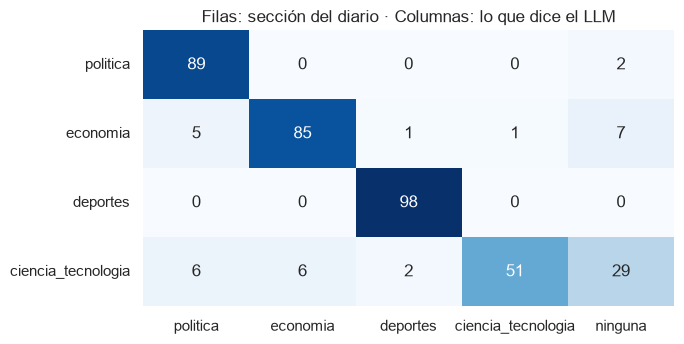

In [4]:
df["acuerdo"] = df.etiqueta_seccion == df.etiqueta_llm
print(f"Acuerdo sección vs LLM: {df.acuerdo.mean():.1%}  ({df.acuerdo.sum()} de {len(df)})\n")

orden = CATEGORIAS + ["ninguna"]
cm = pd.crosstab(df.etiqueta_seccion, df.etiqueta_llm).reindex(index=CATEGORIAS, columns=orden, fill_value=0)
plt.figure(figsize=(7, 3.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Filas: sección del diario · Columnas: lo que dice el LLM")
plt.ylabel(""); plt.xlabel("")
plt.tight_layout(); plt.show()

In [5]:
# ¿La confianza del LLM sirve de algo? Acuerdo con la sección por tramo de confianza.
df["tramo"] = pd.cut(df.confianza, [0, 0.6, 0.8, 0.95, 1.0], include_lowest=True)
print(df.groupby("tramo", observed=True).acuerdo.agg(["mean", "size"]).rename(columns={"mean": "acuerdo", "size": "n"}).round(2))

               acuerdo    n
tramo                      
(-0.001, 0.6]     0.24   17
(0.6, 0.8]        0.55   29
(0.8, 0.95]       0.57   49
(0.95, 1.0]       0.96  287


▎ Cuando el LLM está seguro, casi siempre coincide con la sección: con confianza mayor a 0,95 coinciden el 96 % de las notas (287 de las 382). Cuando duda, coinciden mucho menos: con confianza de 0,6 o menos solo el 24 %. Es decir, la probabilidad que da el modelo sí dice algo sobre cuándo vale la pena desconfiar. Voy a mirar los desacuerdos uno por uno.

In [6]:
pd.set_option("display.max_colwidth", 110)
desac = df[~df.acuerdo].sort_values("confianza", ascending=False)
print(f"{len(desac)} desacuerdos")
desac[["seccion_original", "etiqueta_seccion", "etiqueta_llm", "confianza", "titular"]].reset_index(drop=True)

59 desacuerdos


,seccion_original,etiqueta_seccion,etiqueta_llm,confianza,titular
0,ecologia,ciencia_tecnologia,economia,0.9996,Menos comida y más cara: El Niño amenaza los alimentos y la pesca en Latinoamérica
1,moviles,ciencia_tecnologia,economia,0.9993,"Ventas de ‘smartphones’ registran una caída del 20%, motivado por la crisis de memoria RAM"
2,peru,economia,deportes,0.9935,BTS en Perú: 15 operaciones aéreas y cerca de 1.000 toneladas de carga detrás de sus conciertos
3,actualidad,ciencia_tecnologia,economia,0.9910,"Netflix despedirá a unos 1.000 empleados, el 6 % de su plantilla, según medios"
4,ciencias,ciencia_tecnologia,ninguna,0.9804,León XIV fue operado de cáncer de pulmón: qué implica la extirpación de un lóbulo y cómo es la recuperación
5,actualidad,ciencia_tecnologia,ninguna,0.9770,"Qué es la ""depresión sonriente"" y cómo puedes identificarla"
6,ciberseguridad,ciencia_tecnologia,ninguna,0.9766,Estafas digitales contra adultos mayores: seis recomendaciones para proteger a padres y abuelos
7,actualidad,ciencia_tecnologia,ninguna,0.9744,5 ejercicios para proteger tu cuello del estrés y la mala postura
8,ecologia,ciencia_tecnologia,ninguna,0.9733,El Niño en Perú: no está operativo ninguno de los 18 sistemas de alertas tempranas previstos desde 2017
9,actualidad,ciencia_tecnologia,ninguna,0.9678,"Investigan caso en Siberia: ¿qué sabemos de la peste neumónica? Síntomas, transmisión y tratamiento"


## 3. Auditoría manual

El LLM y la sección no se ponen de acuerdo en 59 noticias, y no quería decidir esos casos con otro modelo. Los revisé yo, con dos listas que este notebook crea en `datos/`:

- revision_desacuerdos.csv: las 59 noticias donde sección y LLM discrepan. En la columna "etiqueta_humana" escribí la categoría que me parece correcta, o "descartar" si la nota no encaja en ninguna de las 4.
- auditoria_muestra.csv: 30 noticias **al azar**. Sirve para saber qué tan buena es la etiqueta por sección en general y no solo en los casos dudosos, que son justo donde ya sabía que había problemas.

Para ir más rápido, la primera lista trae una columna "propuesta_asistente" con una sugerencia de la herramienta de IA que usé para preparar este trabajo. Revisé cada fila y terminé coincidiendo con la propuesta en 58 de 59, así que esa parte no es una segunda opinión del todo independiente. La muestra al azar sí la etiqueté sin sugerencia previa.

In [7]:
RUTA_DES, RUTA_AUD = Path("datos/revision_desacuerdos.csv"), Path("datos/auditoria_muestra.csv")
cols = ["url", "titular", "bajada", "seccion_original", "etiqueta_seccion", "etiqueta_llm", "confianza"]

if not RUTA_DES.exists():
    d = df[~df.acuerdo].sort_values("confianza", ascending=False)[cols].copy()
    d["propuesta_asistente"] = ""
    d["etiqueta_humana"] = ""
    d.to_csv(RUTA_DES, index=False)

if not RUTA_AUD.exists():
    a = df.sample(30, random_state=SEED)[cols].copy()
    a["etiqueta_humana"] = ""
    a.to_csv(RUTA_AUD, index=False)

des = pd.read_csv(RUTA_DES, keep_default_na=False)
aud = pd.read_csv(RUTA_AUD, keep_default_na=False)
print("desacuerdos revisados:", (des.etiqueta_humana != "").sum(), "de", len(des))
print("muestra aleatoria revisada:", (aud.etiqueta_humana != "").sum(), "de", len(aud))

desacuerdos revisados: 59 de 59
muestra aleatoria revisada: 30 de 30


In [8]:
# Si la muestra aleatoria está completa, estimo la calidad de cada fuente de etiquetas.
rev = aud[aud.etiqueta_humana != ""]
if len(rev) >= 20:
    print(f"Sobre {len(rev)} noticias al azar revisadas a mano:")
    print(f"  acierto de la sección del diario : {(rev.etiqueta_seccion == rev.etiqueta_humana).mean():.1%}")
    print(f"  acierto del LLM                  : {(rev.etiqueta_llm == rev.etiqueta_humana).mean():.1%}")
else:
    print("Auditoría aleatoria pendiente: completa 'etiqueta_humana' en datos/auditoria_muestra.csv y vuelve a correr.")

Sobre 30 noticias al azar revisadas a mano:
  acierto de la sección del diario : 93.3%
  acierto del LLM                  : 93.3%


### Etiquetas finales

Regla: la etiqueta final es la **humana** cuando existe (de cualquiera de las dos listas) y, si no, la de la sección.
Las filas marcadas `descartar` salen del dataset y quedan reportadas.

In [9]:
humana = pd.concat([des[["url", "etiqueta_humana"]], aud[["url", "etiqueta_humana"]]])
humana = humana[humana.etiqueta_humana != ""].drop_duplicates("url", keep="first")
validas = set(CATEGORIAS) | {"descartar"}
assert humana.etiqueta_humana.isin(validas).all(), "etiqueta_humana solo admite las 4 categorías o 'descartar'"

df = df.merge(humana, on="url", how="left")
df["etiqueta"] = df.etiqueta_humana.fillna(df.etiqueta_seccion)
df["fuente_etiqueta"] = np.where(df.etiqueta_humana.notna(), "humana", "seccion")

descartadas = df[df.etiqueta == "descartar"]
print(f"Descartadas en la auditoría: {len(descartadas)}")
if len(descartadas):
    display(descartadas[["seccion_original", "etiqueta_llm", "titular"]])
df = df[df.etiqueta != "descartar"].reset_index(drop=True)

print("\nFuente de la etiqueta final:"); print(df.fuente_etiqueta.value_counts().to_string())
print("\nCambiadas respecto a la sección:", (df.etiqueta != df.etiqueta_seccion).sum())
print(df.etiqueta.value_counts().to_string())

# El CSV de entrega lleva las 7 columnas pedidas, con la etiqueta final
df[["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]].to_csv(
    "datos/noticias.csv", index=False, encoding="utf-8")
llm_out = pd.read_csv(RUTA_LLM).merge(df[["url", "etiqueta_seccion", "etiqueta", "fuente_etiqueta"]], on="url")
llm_out.to_csv(RUTA_LLM, index=False)

Descartadas en la auditoría: 12


,seccion_original,etiqueta_llm,titular
155,opinion,politica,Invocación por el Perú
162,peru,deportes,BTS en Perú: 15 operaciones aéreas y cerca de 1.000 toneladas de carga detrás de sus conciertos
170,opinion,ninguna,La gloria gastronómica que debemos multiplicar
186,dia-1,ninguna,"Alberto Goachet, director general del Grupo Fahrenheit: “Mi primer trabajo fue ser ilustrador en un medio ..."
292,robotica,ninguna,Alemania investiga una presunta agresión sexual con un robot contra joven de 16 años
300,actualidad,ninguna,Millones de personas podrían tener que abandonar sus hogares por el cambio climático en el sudeste asiático
327,ecologia,politica,"Demetrio Pacheco, defensor ambiental en Perú: “El Estado podría haber evitado el asesinato de mi hijo” | E..."
329,actualidad,ninguna,"Qué es la ""depresión sonriente"" y cómo puedes identificarla"
332,streamers,ninguna,"¡Ya güey!: Edgar, niño cuya caída se convirtió en fenómeno viral hace 20 años, se casa"
348,ciencias,ninguna,Día Mundial del Huevo: solo el 4% de las gallinas utilizadas en la industria peruana vive libre de jaulas



Fuente de la etiqueta final:
fuente_etiqueta
seccion    296
humana      74

Cambiadas respecto a la sección: 10
etiqueta
deportes              98
politica              97
economia              93
ciencia_tecnologia    82


## 4. Partición 70 / 15 / 15

Estratificada por etiqueta y con semilla fija. Desde aquí el **test no se mira** hasta la evaluación final.
La validación sirve para elegir hiperparámetros y el mejor *epoch*.

In [10]:
df["label"] = df.etiqueta.map(cat2id)
train_df, tmp_df = train_test_split(df, test_size=0.30, random_state=SEED, stratify=df.label)
val_df, test_df = train_test_split(tmp_df, test_size=0.50, random_state=SEED, stratify=tmp_df.label)

for nombre, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{nombre:<6}{len(d):>4}  ", d.etiqueta.value_counts().reindex(CATEGORIAS).tolist())

pd.concat([train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")])[
    ["url", "split"]].to_csv("datos/split.csv", index=False)

train  259   [68, 65, 69, 57]
val     55   [14, 14, 14, 13]
test    56   [15, 14, 15, 12]


## 5. Modelos a comparar

Todos ven **solo el titular** (es lo que el dashboard recibirá), se entrenan con *train* y se eligen con *val*.
Del más barato al más caro:

| # | Modelo | Qué aporta |
|---|---|---|
| 0 | Subsección como predictor | piso «tramposo»: mide cuánto de la tarea es solo saber de qué subsección viene la nota |
| 1 | Zero-shot XNLI en español | sin entrenar nada |
| 2 | TF-IDF + regresión logística | el «Ctrl+F sofisticado» de la clase 8 |
| 3 | Embeddings `multilingual-e5-small` + regresión logística | los embeddings de la clase 8, con un clasificador lineal encima |
| 4 | LLM Qwen 1.5B zero-shot | el etiquetador de arriba, evaluado como clasificador |
| 5 | **BETO** (BERT en español) con fine-tuning | el modelo que se despliega |

In [11]:
def metricas(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred), "f1_macro": f1_score(y_true, y_pred, average="macro")}

resultados = {}           # nombre -> dict(val, test, latencia)
pred_test = {}            # nombre -> predicciones sobre test (para analizar errores)
y_val, y_test = val_df.label.to_numpy(), test_df.label.to_numpy()

def latencia_ms(fn, textos, n=20):
    fn(textos[:2])
    t0 = time.perf_counter()
    for t in textos[:n]:
        fn([t])
    return (time.perf_counter() - t0) / n * 1000

### 5.0 · El piso tramposo: predecir por subsección

In [12]:
# Para cada subsección, la categoría más frecuente en train. Subsecciones no vistas -> la clase más común.
mayoritaria = train_df.groupby("seccion_original").label.agg(lambda s: s.mode().iloc[0])
por_defecto = train_df.label.mode().iloc[0]
pred = test_df.seccion_original.map(mayoritaria).fillna(por_defecto).astype(int).to_numpy()
resultados["0 · Subsección (trampa)"] = {"val": metricas(y_val, val_df.seccion_original.map(mayoritaria).fillna(por_defecto).astype(int)),
                                          "test": metricas(y_test, pred), "lat_ms": 0.0}
print("Con solo la subsección, sin leer el texto:", {k: round(v, 3) for k, v in resultados["0 · Subsección (trampa)"]["test"].items()})

Con solo la subsección, sin leer el texto: {'accuracy': 0.893, 'f1_macro': 0.892}


Este número es la vara para juzgar a los demás: **un modelo que no lo supere con claridad no demuestra haber aprendido nada del texto**, solo de qué sección viene la nota. También me avisa de cuánto de la tarea es «fácil» por cómo se construyeron las categorías: como las etiquetas salen de la sección, la sección las predice casi sola.


### 5.1 · Zero-shot XNLI en español

In [13]:
from transformers import pipeline

zs = pipeline("zero-shot-classification", model="Recognai/bert-base-spanish-wwm-cased-xnli", device="cpu")
etiquetas_es = ["política", "economía", "deportes", "ciencia y tecnología"]
a_cat = dict(zip(etiquetas_es, CATEGORIAS))

def zs_predecir(textos):
    out = zs(list(textos), candidate_labels=etiquetas_es, hypothesis_template="Esta noticia trata de {}.")
    out = [out] if isinstance(out, dict) else out
    return np.array([cat2id[a_cat[o["labels"][0]]] for o in out])

p_val, p_test = zs_predecir(val_df.titular), zs_predecir(test_df.titular)
resultados["1 · Zero-shot XNLI"] = {"val": metricas(y_val, p_val), "test": metricas(y_test, p_test),
                                     "lat_ms": latencia_ms(zs_predecir, test_df.titular.tolist())}
pred_test["1 · Zero-shot XNLI"] = p_test
print(resultados["1 · Zero-shot XNLI"]["test"])
del zs

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{'accuracy': 0.5892857142857143, 'f1_macro': 0.5210060558897768}


### 5.2 · TF-IDF + regresión logística

In [14]:
def ajustar_tfidf(C):
    vec = TfidfVectorizer(strip_accents="unicode", lowercase=True, ngram_range=(1, 2), sublinear_tf=True)
    X = vec.fit_transform(train_df.titular)
    clf = LogisticRegression(C=C, max_iter=2000, class_weight="balanced").fit(X, train_df.label)
    return vec, clf

busqueda = {}
for C_ in [0.3, 1, 3, 10, 30, 100]:
    vec, clf = ajustar_tfidf(C_)
    busqueda[C_] = f1_score(y_val, clf.predict(vec.transform(val_df.titular)), average="macro")
print({k: round(v, 3) for k, v in busqueda.items()})
mejor_C = max(busqueda, key=busqueda.get)
print("C elegido con validación:", mejor_C)

vec, clf_tfidf = ajustar_tfidf(mejor_C)
pipe_tfidf = lambda ts: clf_tfidf.predict(vec.transform(list(ts)))
resultados["2 · TF-IDF + LogReg"] = {
    "val": metricas(y_val, pipe_tfidf(val_df.titular)), "test": metricas(y_test, pipe_tfidf(test_df.titular)),
    "lat_ms": latencia_ms(pipe_tfidf, test_df.titular.tolist())}
pred_test["2 · TF-IDF + LogReg"] = pipe_tfidf(test_df.titular)
print(resultados["2 · TF-IDF + LogReg"]["test"])

# Este modelo es chico (cientos de KB): se versiona como plan B del dashboard.
Path("modelo").mkdir(exist_ok=True)
joblib.dump({"vectorizador": vec, "clasificador": clf_tfidf, "categorias": CATEGORIAS}, "modelo/tfidf_logreg.joblib", compress=3)
print("modelo/tfidf_logreg.joblib:", round(Path("modelo/tfidf_logreg.joblib").stat().st_size / 1024), "KB")

{0.3: 0.838, 1: 0.838, 3: 0.856, 10: 0.874, 30: 0.893, 100: 0.874}
C elegido con validación: 30
{'accuracy': 0.7678571428571429, 'f1_macro': 0.7699725885904973}
modelo/tfidf_logreg.joblib: 83 KB


### 5.3 · Embeddings e5 + regresión logística

In [15]:
from sentence_transformers import SentenceTransformer

e5 = SentenceTransformer("intfloat/multilingual-e5-small")
emb = lambda ts: e5.encode([f"query: {t}" for t in ts], normalize_embeddings=True, show_progress_bar=False)
E_tr, E_va, E_te = emb(train_df.titular), emb(val_df.titular), emb(test_df.titular)

busqueda = {}
for C_ in [0.3, 1, 3, 10, 30, 100]:
    c = LogisticRegression(C=C_, max_iter=3000, class_weight="balanced").fit(E_tr, train_df.label)
    busqueda[C_] = f1_score(y_val, c.predict(E_va), average="macro")
print({k: round(v, 3) for k, v in busqueda.items()})
clf_e5 = LogisticRegression(C=max(busqueda, key=busqueda.get), max_iter=3000, class_weight="balanced").fit(E_tr, train_df.label)

pipe_e5 = lambda ts: clf_e5.predict(emb(list(ts)))
resultados["3 · Embeddings e5 + LogReg"] = {
    "val": metricas(y_val, clf_e5.predict(E_va)), "test": metricas(y_test, clf_e5.predict(E_te)),
    "lat_ms": latencia_ms(pipe_e5, test_df.titular.tolist())}
pred_test["3 · Embeddings e5 + LogReg"] = clf_e5.predict(E_te)
print(resultados["3 · Embeddings e5 + LogReg"]["test"])
del e5

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

{0.3: 0.892, 1: 0.91, 3: 0.929, 10: 0.946, 30: 0.946, 100: 0.946}


{'accuracy': 0.8928571428571429, 'f1_macro': 0.8974853011282378}


### 5.4 · El LLM como clasificador

Ya tengo sus probabilidades para todas las noticias (sección 1). Lo evalúo sobre las mismas noticias de val y test
contra la etiqueta final. Ventaja y trampa: el LLM vio titular **y bajada**; los demás modelos, solo el titular. Cuando el LLM
responde «ninguna» cuenta como error, porque en las filas que quedaron todas pertenecen a una de las 4 categorías.

In [16]:
cat_llm = lambda d: d.etiqueta_llm.map(lambda e: cat2id.get(e, -1)).to_numpy()
resultados["4 · LLM Qwen 1.5B zero-shot"] = {
    "val": metricas(y_val, cat_llm(val_df)), "test": metricas(y_test, cat_llm(test_df)), "lat_ms": float("nan")}
pred_test["4 · LLM Qwen 1.5B zero-shot"] = cat_llm(test_df)
print(resultados["4 · LLM Qwen 1.5B zero-shot"]["test"])

{'accuracy': 0.8928571428571429, 'f1_macro': 0.7135335558027438}


### 5.5 · Fine-tuning de BETO

BETO (`dccuchile/bert-base-spanish-wwm-cased`) es un BERT preentrenado solo con texto en español, a diferencia del
DistilBERT multilingüe, que reparte su capacidad entre más de 100 idiomas. Es la opción lógica para titulares peruanos.
Hiperparámetros: 6 épocas, *learning rate* 3e-5, *batch* 16, y me quedo con el *epoch* de mejor F1 en **validación**.

Se entrena con **3 semillas** porque con 266 ejemplos de entrenamiento el resultado de una sola corrida puede ser suerte.

In [17]:
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments, set_seed)

MODELO_BASE = "dccuchile/bert-base-spanish-wwm-cased"
tok = AutoTokenizer.from_pretrained(MODELO_BASE)

class Titulares(torch.utils.data.Dataset):
    def __init__(self, d):
        self.enc = tok(d.titular.tolist(), truncation=True, max_length=64)
        self.y = d.label.tolist()
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        return {**{k: v[i] for k, v in self.enc.items()}, "labels": self.y[i]}

ds_tr, ds_va, ds_te = Titulares(train_df), Titulares(val_df), Titulares(test_df)

def cm_(ep):
    p = ep.predictions.argmax(-1)
    return metricas(ep.label_ids, p)

def entrenar(seed):
    set_seed(seed)
    modelo = AutoModelForSequenceClassification.from_pretrained(
        MODELO_BASE, num_labels=4, id2label=id2cat, label2id=cat2id)
    with tempfile.TemporaryDirectory() as tmp:               # los checkpoints no se quedan en el repo
        args = TrainingArguments(
            output_dir=tmp, num_train_epochs=6, learning_rate=3e-5, weight_decay=0.01, warmup_steps=0.1,
            per_device_train_batch_size=16, per_device_eval_batch_size=32,
            eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
            load_best_model_at_end=True, metric_for_best_model="f1_macro", greater_is_better=True,
            logging_steps=5, report_to="none", seed=seed, use_cpu=not torch.cuda.is_available())
        tr = Trainer(model=modelo, args=args, train_dataset=ds_tr, eval_dataset=ds_va,
                     data_collator=DataCollatorWithPadding(tok), compute_metrics=cm_)
        tr.train()
    return tr

corridas = {}
for s in [42, 7, 2026]:
    t0 = time.time()
    corridas[s] = entrenar(s)
    p = corridas[s].predict(ds_te)
    corridas[s].test_pred = p.predictions.argmax(-1)
    print(f"semilla {s}: {time.time() - t0:.0f} s · val F1 {corridas[s].evaluate()['eval_f1_macro']:.3f} · test F1 {p.metrics['test_f1_macro']:.3f}")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.007023,0.719037,0.800000,0.760103
2,0.337966,0.279806,0.909091,0.906258
3,0.212385,0.232194,0.909091,0.909888
4,0.091343,0.230569,0.945455,0.945106
5,0.032128,0.249043,0.927273,0.927198
6,0.020433,0.238818,0.927273,0.927198


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.007665,0.245591,6,0.945455,0.945648


semilla 2026: 182 s · val F1 0.946 · test F1 0.857


BETO, F1 macro en test con 3 semillas: [0.874 0.905 0.857] -> media 0.879 ± 0.020


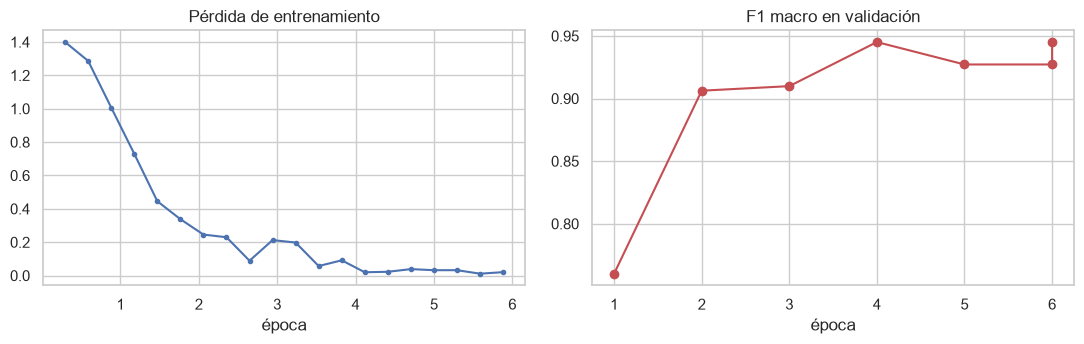

In [18]:
tr42 = corridas[42]
f1s = [f1_score(y_test, corridas[s].test_pred, average="macro") for s in corridas]
print(f"BETO, F1 macro en test con 3 semillas: {np.round(f1s, 3)} -> media {np.mean(f1s):.3f} ± {np.std(f1s):.3f}")

# Curva de aprendizaje de la corrida principal (semilla 42)
h = pd.DataFrame(tr42.state.log_history)
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
h.dropna(subset=["loss"]).plot(x="epoch", y="loss", ax=ejes[0], legend=False, marker="o", ms=3)
ejes[0].set_title("Pérdida de entrenamiento"); ejes[0].set_xlabel("época")
h.dropna(subset=["eval_f1_macro"]).plot(x="epoch", y="eval_f1_macro", ax=ejes[1], legend=False, marker="o", color="#C44E52")
ejes[1].set_title("F1 macro en validación"); ejes[1].set_xlabel("época")
plt.tight_layout(); plt.show()

In [19]:
# Latencia real de inferencia (un titular a la vez, CPU)
tr42.model.eval()
def beto_predecir(ts):
    x = tok(list(ts), return_tensors="pt", truncation=True, max_length=64, padding=True).to(tr42.model.device)
    with torch.no_grad():
        return tr42.model(**x).logits.argmax(-1).cpu().numpy()

resultados["5 · BETO fine-tuned"] = {
    "val": metricas(y_val, tr42.predict(ds_va).predictions.argmax(-1)),
    "test": metricas(y_test, tr42.test_pred),
    "lat_ms": latencia_ms(beto_predecir, test_df.titular.tolist()),
    "f1_test_3_semillas": [round(x, 4) for x in f1s]}
pred_test["5 · BETO fine-tuned"] = tr42.test_pred

tabla = pd.DataFrame({
    n: {"F1 val": r["val"]["f1_macro"], "F1 test": r["test"]["f1_macro"], "Acc test": r["test"]["accuracy"], "ms/titular": r["lat_ms"]}
    for n, r in resultados.items()}).T
tabla.round(3)

,F1 val,F1 test,Acc test,ms/titular
0 · Subsección (trampa),0.885,0.892,0.893,0.000
1 · Zero-shot XNLI,0.533,0.521,0.589,114.160
2 · TF-IDF + LogReg,0.893,0.770,0.768,0.410
3 · Embeddings e5 + LogReg,0.946,0.897,0.893,14.772
4 · LLM Qwen 1.5B zero-shot,0.735,0.714,0.893,NaN
5 · BETO fine-tuned,0.945,0.874,0.875,29.627


## 6. Evaluación final en el test reservado

Matriz de confusión y reporte por clase del modelo desplegado (BETO, semilla 42), **sobre el test**, nunca sobre train.

                    precision    recall  f1-score   support

          politica      0.857     0.800     0.828        15
          economia      0.833     0.714     0.769        14
          deportes      0.882     1.000     0.938        15
ciencia_tecnologia      0.923     1.000     0.960        12

          accuracy                          0.875        56
         macro avg      0.874     0.879     0.874        56
      weighted avg      0.872     0.875     0.871        56



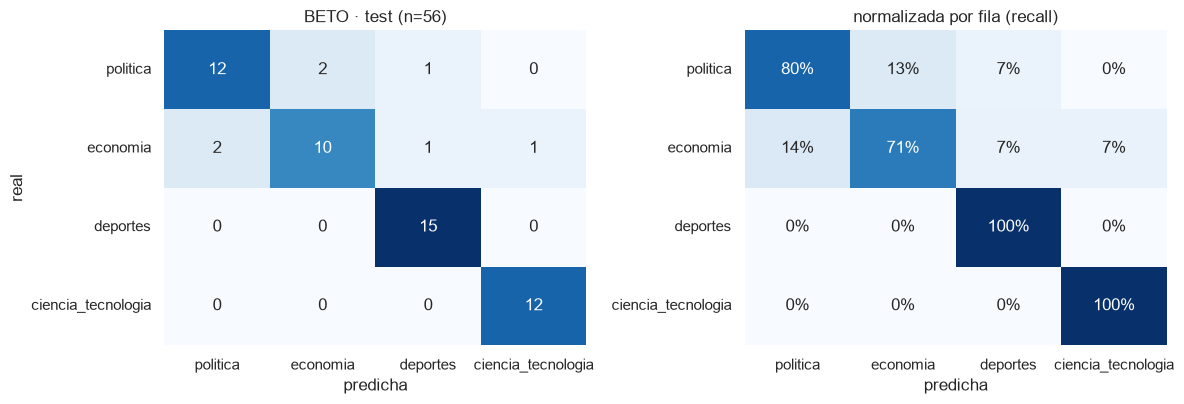

In [20]:
y_hat = pred_test["5 · BETO fine-tuned"]
print(classification_report(y_test, y_hat, target_names=CATEGORIAS, digits=3))

cm = confusion_matrix(y_test, y_hat)
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=CATEGORIAS, yticklabels=CATEGORIAS, ax=ejes[0])
ejes[0].set_title(f"BETO · test (n={len(y_test)})"); ejes[0].set_xlabel("predicha"); ejes[0].set_ylabel("real")
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".0%", cmap="Blues", cbar=False,
            xticklabels=CATEGORIAS, yticklabels=CATEGORIAS, ax=ejes[1])
ejes[1].set_title("normalizada por fila (recall)"); ejes[1].set_xlabel("predicha"); ejes[1].set_ylabel("")
plt.tight_layout(); plt.show()

In [21]:
# Los errores, uno por uno: lo que hay que leer antes de escribir conclusiones
conf = torch.softmax(torch.tensor(tr42.predict(ds_te).predictions), -1).max(-1).values.numpy()
err = test_df.assign(predicha=[id2cat[i] for i in y_hat], p=conf.round(2))
err = err[err.etiqueta != err.predicha]
print(f"{len(err)} errores de {len(test_df)}")
err[["seccion_original", "etiqueta", "predicha", "p", "titular"]].reset_index(drop=True)

7 errores de 56


,seccion_original,etiqueta,predicha,p,titular
0,ecologia,politica,economia,0.87,Perú: más de 200 operativos en el año en Madre de Dios no logran frenar el avance de la minería ilegal en ...
1,opinion,economia,ciencia_tecnologia,0.92,"La gran transformación del patrimonio: nuevas generaciones, nuevas decisiones"
2,actualidad,politica,deportes,0.80,"César Acuña anuncia su retiro: “Chau política, dedicado a tiempo completo a formar a mis jóvenes”"
3,mundo,economia,politica,0.98,"EE.UU. busca sostener su liderazgo turístico pese al retroceso de visitantes, ¿cómo planea lograrlo el gob..."
4,mundo,economia,politica,0.97,"Justin Trudeau, exprimer ministro de Canadá, sobre crisis de turismo en EE.UU.: “No han sido muy buenos ha..."
5,gobierno,politica,economia,0.84,Unión Europea y Minem acuerdan creación de mesa técnica para destrabar permisos e infraestructura
6,opinion,economia,deportes,0.99,AlaCena no tiene precio


## 7. Qué aprendí

**Las etiquetas.** Sección y LLM coinciden en el 84,6 % de las 382 noticias. Casi todo el desacuerdo está en
`ciencia_tecnologia`: ahí Qwen respondió «ninguna» en 29 notas, y casi todas son salud, clima y ambiente o
estilo de vida que El Comercio publica en la sección de tecnología. En la auditoría, 12 notas se descartaron y 10
cambiaron de categoría; quedaron **370 noticias** (97 / 93 / 98 / 82). La muestra aleatoria de 30 dio 93,3 % de
acierto tanto para la sección como para el LLM. Con n = 30 el margen es de ±9 puntos, así que no distingue
entre ambas fuentes, pero sí dice que la sección es buena y no perfecta.
La confianza del LLM sirvió: sobre 0,95 coincide con la sección el 96 % de las veces; bajo 0,6, solo el 24 %.

**La comparación.** Sobre el test (56 noticias; una noticia mueve ≈ 1,8 puntos de F1) los modelos quedan así:
embeddings e5 + regresión logística 0,897, BETO 0,874 (0,879 ± 0,020 con 3 semillas), TF-IDF 0,770, Qwen 0,714
y zero-shot XNLI 0,521. Dos lecturas honestas:

1. **BETO no le gana a e5 + regresión logística**, y la diferencia (1–2 noticias) está dentro del ruido. Con 259
   titulares de entrenamiento, un clasificador lineal sobre buenos embeddings rinde igual que un fine-tuning
   completo, y 2 veces más rápido. Lo desplegué porque la tarea pide un Transformer afinado, no porque salga ganador.
2. **Predecir por subsección, sin leer el texto, da F1 0,892.** Ningún modelo supera esa vara con claridad. La
   razón es que las etiquetas nacen de la sección: un modelo que aprenda «de qué parte del diario viene» acierta casi
   sin leer. Antes de la auditoría ese piso era 0,964, y bajó a 0,892 al corregir etiquetas por contenido. Por eso el
   F1 de BETO **mide cuánto coincide con la clasificación del diario, no cuánto entiende de noticias**.

**Los errores de BETO (7 de 56).** Leídos uno por uno:
- Cuatro vienen de notas con etiqueta discutible o sin pistas temáticas: dos columnas de opinión de título
  críptico («AlaCena no tiene precio» salió `deportes` con 99 %) y dos notas de `mundo` sobre turismo en EE. UU.
  Las etiquetamos `economia` por la sección, pero son política internacional tanto como economía; el modelo las
  llamó `politica` con 97–98 % de confianza.
- Dos confunden `politica` con `economia`: la mesa técnica entre la UE y el Minem por permisos e
  infraestructura, y los operativos contra la minería ilegal en Tambopata. Es la frontera difusa de siempre: la
  política pública habla de plata.
- «César Acuña anuncia su retiro: “Chau política…”» salió `deportes`. No tengo una explicación comprobada;
  el titular es coloquial y casi todo su peso está en un nombre propio, así que el modelo tenía pocas pistas temáticas.
- `ciencia_tecnologia` y `deportes` salen con recall 1,00 y vocabulario propio; `economia` es la clase
  más floja (recall 0,71).

**Límites que no puedo arreglar con más épocas.**
- Test chico (56): los intervalos son anchos y las diferencias entre modelos de 1–2 noticias no son conclusivas.
- Cada categoría cubre una ventana distinta: deportes son solo 3 días. Palabras de la semana (una final, un
  fichaje) pueden pesar más que el vocabulario temático.
- La auditoría de los 59 desacuerdos partió de una propuesta asistida y fue casi igual a ella (58 de 59). Los 30
  casos al azar sí son una revisión independiente.
- El modelo siempre elige una de las 4 categorías, aunque la noticia no pertenezca a ninguna: en el dashboard,
  un titular sobre un gato perdido sale como ciencia y tecnología con 90 % de confianza. Una versión mejor
  necesitaría una quinta salida «otra» o un umbral calibrado.

In [22]:
# Guardar el modelo desplegable y las métricas oficiales (todo sale del código, nada escrito a mano)
tr42.save_model("modelo")
tok.save_pretrained("modelo")

peso_mb = sum(f.stat().st_size for f in Path("modelo").rglob("*") if f.is_file() and "checkpoints" not in f.parts) / 1e6
print(f"modelo/ pesa {peso_mb:.0f} MB -> está en .gitignore; el dashboard recurre al modelo TF-IDF si no lo encuentra")

metricas_json = {
    "fecha_extraccion": df.fecha.max(),
    "n_noticias": int(len(df)),
    "n_train": len(train_df), "n_val": len(val_df), "n_test": len(test_df),
    "categorias": CATEGORIAS,
    "conteo_por_categoria": df.etiqueta.value_counts().reindex(CATEGORIAS).astype(int).to_dict(),
    "acuerdo_seccion_vs_llm": round(float(df.acuerdo.mean()), 4),
    "etiquetas_corregidas_a_mano": int((df.etiqueta != df.etiqueta_seccion).sum()),
    "modelo_desplegado": "BETO (dccuchile/bert-base-spanish-wwm-cased), fine-tuning, semilla 42",
    "f1_test": round(resultados["5 · BETO fine-tuned"]["test"]["f1_macro"], 4),
    "acc_test": round(resultados["5 · BETO fine-tuned"]["test"]["accuracy"], 4),
    "f1_test_3_semillas": resultados["5 · BETO fine-tuned"]["f1_test_3_semillas"],
    "comparacion": {n: {"f1_macro_test": round(r["test"]["f1_macro"], 4), "accuracy_test": round(r["test"]["accuracy"], 4),
                        "ms_por_titular": None if np.isnan(r["lat_ms"]) else round(r["lat_ms"], 1)}
                    for n, r in resultados.items()},
    "reporte_por_clase": classification_report(y_test, y_hat, target_names=CATEGORIAS, output_dict=True, digits=4),
    "matriz_confusion": cm.tolist(),
}
Path("datos/metricas.json").write_text(json.dumps(metricas_json, ensure_ascii=False, indent=2), encoding="utf-8")

test_df.assign(predicha=[id2cat[i] for i in y_hat], confianza=conf.round(4))[
    ["url", "titular", "etiqueta", "predicha", "confianza"]].to_csv("datos/predicciones_test.csv", index=False)
print("guardado: datos/metricas.json, datos/predicciones_test.csv")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

modelo/ pesa 440 MB -> está en .gitignore; el dashboard recurre al modelo TF-IDF si no lo encuentra
guardado: datos/metricas.json, datos/predicciones_test.csv
